# Setup

In [2]:
# Load necessary packages.
suppressPackageStartupMessages({
    library(glue)
    library(tidyverse)
    library(Matrix)
    library(tictoc)
    library(parallel)
    library(tibble)
    library(data.table)
    library(DESeq2)
    library(data.table)
    library(purrr)
    library(BiocManager)
})

simulation_dir = "results/for_real_comp"
# simulation_dir = "results/for_hier_norm"

# Load up functions from utils. 
source(glue("../../tools/Flipper_utils.r"))

In [3]:
dir.create(glue("{simulation_dir}/flipper/tables"), recursive = TRUE, showWarnings = FALSE)
dir.create(glue("{simulation_dir}/flipper/intermediates"), recursive = TRUE, showWarnings = FALSE)

# Modified functions

In [4]:
volcano_plot = function(data, 
                       padj_threshold = 0.05, 
                       log2fc_threshold = 1.0,
                       top_n = 10,
                       colors = NULL,
                       plot_width = 1,
                       inside_legend = FALSE) {

    data = as.data.frame(data)
    
    if (nrow(data) < 1) {
        p = ggplot() + 
            theme_void() +
            labs(title = "Error",
                 subtitle = "No data available (Treatment/Control)") +
            theme(plot.title = element_text(hjust = 0.5, face = "bold"),
                  plot.subtitle = element_text(hjust = 0.5))
        return(p)
    }
    
    # compute transformed p-values and significance
    data$neg_log10_padj = -log10(pmax(data$padj, 0))
    data$significance = "Not Significant"
    data$significance[data$padj < padj_threshold & data$log2FoldChange > log2fc_threshold] = "Up"
    data$significance[data$padj < padj_threshold & data$log2FoldChange < -log2fc_threshold] = "Down"
    data$significance[data$padj < padj_threshold & abs(data$log2FoldChange) <= log2fc_threshold] = "Pass p-value cutoff"
    
    # top genes for labelINf
    top_genes = data[data$significance != "Not Significant", ]
    top_genes = top_genes[order(top_genes$padj), ]
    top_genes = head(top_genes, top_n)
    top_genes$label = top_genes$gene_name
    
    # symmetric x-limit
    max_l2fc = max(abs(data$log2FoldChange), na.rm = TRUE)

    # --- Y-limit based on 5th highest * 1.5 ---
    vals <- data$neg_log10_padj[is.finite(data$neg_log10_padj)]
    if (length(vals) > 0) {
      q1 <- quantile(vals, 0.05, na.rm = TRUE)
      q3 <- quantile(vals, 0.95, na.rm = TRUE)
      iqr <- q3 - q1
      fence <- q3 + 8 * iqr
      capped <- vals[vals <= fence]
      if (length(capped) == 0) {
        ymax <- max(vals)
      } else {
        ymax <- max(capped) * 1.1
      }
      ymax <- max(ymax, 3)
    } else {
      ymax <- 3
    }

    # build plot
    p = ggplot(data, aes(x = log2FoldChange, y = neg_log10_padj, color = significance)) +
      geom_point(alpha = 0.5, size = 2) +
      scale_color_manual(
        values = c(
          "Not Significant" = "gray70",
          "Up" = "red",
          "Down" = "blue",
          "Pass p-value cutoff" = "black"
        ),
        name = "Significance (Treatment/Control)" 
      ) +
      geom_vline(xintercept = c(-log2fc_threshold, log2fc_threshold),
                 linetype = "dashed", color = "black", linewidth = 0.5) +
      geom_hline(yintercept = -log10(padj_threshold),
                 linetype = "dashed", color = "black", linewidth = 0.5) +
      labs(
        x = expression("Log"[2]*" fold change"),
        y = expression("-Log"[10]*"(adjusted p-value)")
      ) +
      coord_cartesian(xlim = c(-6, 6), ylim = c(0, 8)) +
      theme_minimal() +
      theme(
        panel.grid.major = element_line(color = "gray90", linewidth = 0.3),
        panel.grid.minor = element_blank(),
        panel.background = element_rect(fill = "white", color = NA),
        plot.background = element_rect(fill = "white", color = NA),
        plot.title = element_text(hjust = 0.5, face = "bold"),
        axis.title = element_text(size = 12),
        axis.text = element_text(size = 10),
        legend.position = "right",
        legend.title = element_text(size = 10, face = "bold"),
        legend.text = element_text(size = 8),
        legend.key.size = unit(0.5, "cm"))
  
    return(p)
}

# Run preprocessINf

In [5]:
# Load up count data. 
count_data = read.csv(paste0(simulation_dir,"/window_counts/window_counts.tsv"),sep = "\t")

ctrl = "control"
trt = "treatment"

write.table(count_data, glue("{simulation_dir}/flipper/intermediates/all_count_data.tsv"), sep="\t", row.names = FALSE)

# Load up the window data. 
window_data = load_and_combine_window(paste0(simulation_dir, "/skipper"), ctrl, trt)

# Get the individual count data from each rep for each window. 
window_counts_INw = make_INw(ctrl, trt, window_data, count_data, paste0(simulation_dir, "/flipper")) 
write.table(window_counts_INw, paste0(simulation_dir, "/flipper/intermediates/window_counts_INw.tsv"), row.names = FALSE, sep = "\t")

# Calculate genewise IN by summing over gene name in the count data. 
feature_wise_IN = get_feature_wise(count_data, ctrl, trt)$feature_wise_IN

# Calculate genewise IN by summing over gene name in the count data. 
gene_wise = get_gene_wise(count_data, ctrl, trt)

# Replace the window wise IN counts with the gene wise IN counts and save. 
junk = replace_window_IN_count(window_counts_INw, feature_wise_IN, ctrl, trt, paste0(simulation_dir, "/flipper"))

Joining with `by = join_by(gene_name, feature_type, feature_id, window_name)`


# Run calc_norm

In [6]:
get_window_counts = function(count_data, skipper_dir, sample_cond, cond) {
    windows = read.csv(paste0(skipper_dir, '/reproducible_enriched_windows/',sample_cond,'.reproducible_enriched_windows.tsv.gz'),
                              sep = '\t')
    trt_cols = get_reps_IP_only(count_data, cond)   
    IP_cols <- c(trt_cols, "gene_name", "window_name")
    window_counts = dplyr::select(left_join(windows, count_data), all_of(IP_cols))
    background_counts = dplyr::select(anti_join(count_data, windows), all_of(IP_cols))
    return(list(window_counts = window_counts, background_counts = background_counts))
}

In [7]:
get_sf_MOR = function(data) {
    # Pick only count columns. 
    count_cols <- setdiff(names(data),
                          c("gene_name","window_name"))
    
    # Coerce to plain numeric matrix.
    counts_df <- as.data.frame(data[, count_cols, drop = FALSE])
    counts_df[] <- lapply(counts_df, function(x) as.numeric(as.character(x)))
    counts <- as.matrix(counts_df)
    
    # Set gene rownames. 
    rownames(counts) <- as.character(data$gene_name)
    
    # Remove rows with any NA. 
    ok <- complete.cases(counts)
    counts <- counts[ok, , drop = FALSE]
    storage.mode(counts) <- "numeric"  # ensure numeric
    
    # Get size factors. 
    sf <- DESeq2::estimateSizeFactorsForMatrix(counts, type = "poscounts")
    return(sf)
}

In [8]:
# Calculate genewise IN by summing over gene name in the count data. 
count_data = read.csv(paste0(simulation_dir, "/flipper/intermediates/all_count_data.tsv"), sep = '\t')
gene_wise_IN = gene_wise$gene_wise_IN
gene_wise_IP = gene_wise$gene_wise_IP

# A weak filter is required to avoid potential errors from many zero count rows. 
ctrl_cols  <- get_reps(count_data, ctrl)  
trt_cols  <- get_reps(count_data, trt)  
just_counts <- c(ctrl_cols, trt_cols)
filtered_counts = count_data[rowMeans(count_data[just_counts]) > 1,]

In [9]:
# Load up the reproducible windows for each treatment group. 
IP_ctrl = get_window_counts(filtered_counts, paste0(simulation_dir, "/skipper"), ctrl, ctrl)
IP_trt = get_window_counts(filtered_counts, paste0(simulation_dir, "/skipper"), trt, trt)
window_ctrl = IP_ctrl$window_counts
window_trt = IP_trt$window_counts
background_ctrl = IP_ctrl$background_counts
background_trt = IP_trt$background_counts

# Get the rep counts for later.
reps_trt <- as.integer(
  sub(".*_(IN|IP)_", "", grep(paste0("^", trt, "_"), names(filtered_counts), value = TRUE))
) |> unique()
reps_ctrl <- as.integer(
  sub(".*_(IN|IP)_", "", grep(paste0("^", ctrl, "_"), names(filtered_counts), value = TRUE))
) |> unique()

Joining with `by = join_by(gene_name, feature_type, feature_id, window_name)`
Joining with `by = join_by(gene_name, feature_type, feature_id, window_name)`
Joining with `by = join_by(gene_name, feature_type, feature_id, window_name)`
Joining with `by = join_by(gene_name, feature_type, feature_id, window_name)`


In [10]:
# NOTE: These size factors are calculated solely for the purposes of being used for the 
# demonstrate_hier_norm_need.ipynb notebook, and generally should not be used. 

IN_sf = get_sf_MOR(gene_wise_IN[, setdiff(names(gene_wise_IN), c("gene_name","length", "gc", "window_name"))])
IP_sf_backg = get_sf_MOR(gene_wise_IP[, setdiff(names(gene_wise_IP), c("gene_name","length", "gc", "window_name"))])
norm_factors_backg = c(IN_sf, IP_sf_backg)
# Save the size factors. 
write.table(data.frame(Sample = names(norm_factors_backg), SizeFactor = norm_factors_backg),
          paste0(simulation_dir, "/flipper/intermediates/normalization_factors_backg.tsv"), row.names = FALSE, sep = "\t")

Warning message:
“Unknown or uninitialised column: `gene_name`.”
Warning message:
“Unknown or uninitialised column: `gene_name`.”


In [11]:
# Calculate size factors for the input. 
IN_sf = get_sf_MOR(gene_wise_IN[, setdiff(names(gene_wise_IN), c("gene_name","length", "gc", "window_name"))])

# Calculate norm factors for the treatment and ctrl IPs seperately. 
IP_ctrl_sf <- get_sf_MOR(window_ctrl[, setdiff(names(window_ctrl), c("gene_name", "window_name"))])
IP_trt_sf <- get_sf_MOR(window_trt[, setdiff(names(window_trt), c("gene_name","window_name"))])

# Combine into one vector.
temp_norm_factors <- c(IP_trt_sf, IP_ctrl_sf, IN_sf)

# Build the vector of column names for control IP replicates
ctrl_cols = names(IP_ctrl_sf)

# Same for treatment IP replicates
trt_cols  = names(IP_trt_sf)

# Keep only background windows present in both conditions. 
background_both = inner_join(background_ctrl, background_trt, by = "window_name", suffix = c("_ctrl", "_trt"))

# Sum them as new columns.
background_both[[paste0(ctrl, "_IP_sum")]] = rowSums(background_both[paste0(ctrl_cols)], na.rm = TRUE)
background_both[[paste0(trt, "_IP_sum")]]  = rowSums(background_both[paste0(trt_cols)],  na.rm = TRUE)

# Collapse background windows to genes.
background_gene = background_both %>%
    group_by(gene_name_ctrl) %>%
    summarise(across(all_of(c(paste0(ctrl, "_IP_sum"), paste0(trt, "_IP_sum"))), ~ sum(.x, na.rm = TRUE)), .groups = "drop") %>%
    dplyr::rename(gene_name = gene_name_ctrl)

# Size factors for average.
ctrl_sum_col = paste0(ctrl, "_IP_sum")
trt_sum_col  = paste0(trt, "_IP_sum")
IP_backg_sf = get_sf_MOR(dplyr::select(background_gene, gene_name, all_of(c(ctrl_sum_col, trt_sum_col))))

# Combine the rep specific size factors with the average background size factors. 
norm_factors = combine_ip_size_factors(temp_norm_factors, IP_backg_sf, ctrl, trt)

Warning message:
“Unknown or uninitialised column: `gene_name`.”


In [12]:
write.table(data.frame(Sample = names(norm_factors), SizeFactor = norm_factors),
          paste0(simulation_dir, "/flipper/intermediates/normalization_factors.tsv"), row.names = FALSE, sep = "\t")

# Run differential analysis

In [13]:
# Main steps
window_counts = read.csv(paste0(simulation_dir, "/flipper/intermediates/window_counts_INf.tsv"), sep = "\t")

# Define the columns you want to keep in the order you would like them. 
ctrl_cols  = get_reps(window_counts, ctrl)
trt_cols  = get_reps(window_counts, trt)   
select_cols = c(ctrl_cols, trt_cols)

# Run the differential analysis. 
result = process_differential(window_counts, norm_factors, ctrl, trt, select_cols, 0.05, 1)
groups=c("IP","Trt") # for PCA analysis

# Save results. 
write.table(result$result_check, file = paste0(simulation_dir, "/flipper/tables/all_windows.tsv"), sep="\t", row.names = FALSE, quote = FALSE)
write.table(result$sigs, file = paste0(simulation_dir, "/flipper/tables/differential_windows.tsv"), sep="\t", row.names = FALSE, quote = FALSE)

# Create and save volcano plot (for supplemental figure 2D). 
Volcano = volcano_plot(result$result_check)
ggsave(paste0(simulation_dir, "/flipper/Sim_Flipper_Volcano_Fig_S2D.png"),
       plot = Volcano, width = 6, height = 4, device = "png")


Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



In [15]:
# Create and save volcano plot (for supplemental figure 2D). 
Volcano = volcano_plot(result$result_check)
ggsave(paste0(simulation_dir, "/flipper/Sim_Flipper_Volcano_Fig_S2D.png"),
       plot = Volcano, width = 6, height = 4, device = "png")

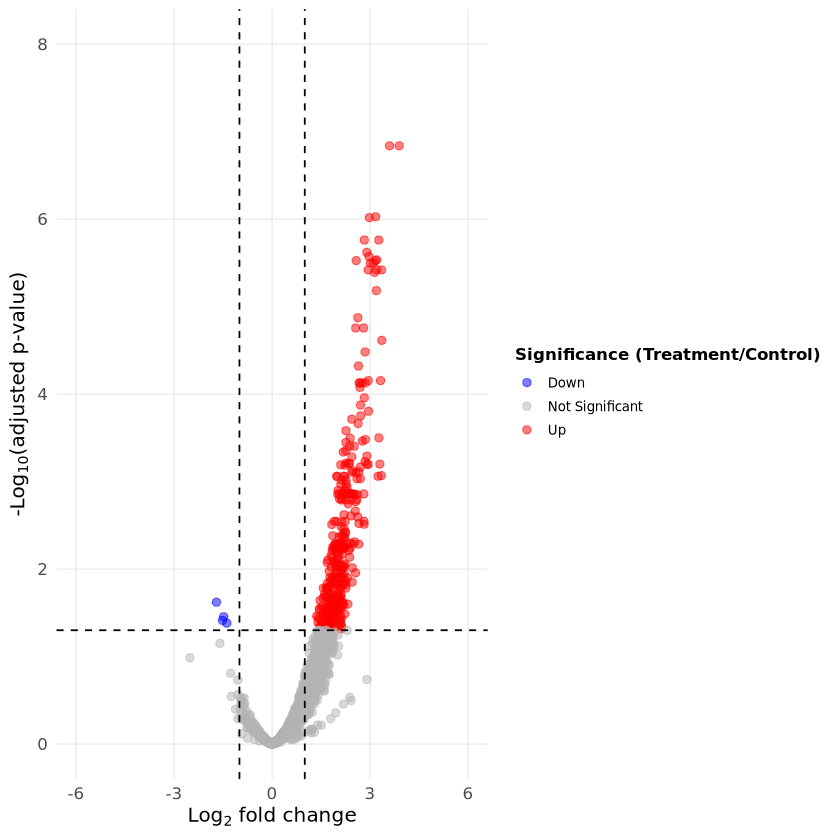

In [16]:
Volcano

In [19]:
# # NOTE: This second run is meant to show the problems with background normalization. 

# # Main steps
# window_counts = read.csv(paste0(simulation_dir, "/flipper/intermediates/window_counts_INf.tsv"), sep = "\t")

# # Define the columns you want to keep in the order you would like them. 
# ctrl_cols  = get_reps(window_counts, ctrl)
# trt_cols  = get_reps(window_counts, trt)   
# select_cols = c(ctrl_cols, trt_cols)

# # Run the differential analysis. 
# result = process_differential(window_counts, norm_factors_backg, ctrl, trt, select_cols, 0.05, 1)
# groups=c("IP","Trt") 

# # Create and save volcano plot (for supplemental figure 2D). 
# Volcano = volcano_plot(result$result_check)
# ggsave(paste0(simulation_dir, "/Sim_Flipper_Volcano_Fig_S2D_backg.png"),
#        plot = Volcano, width = 6, height = 4, device = "png")


Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



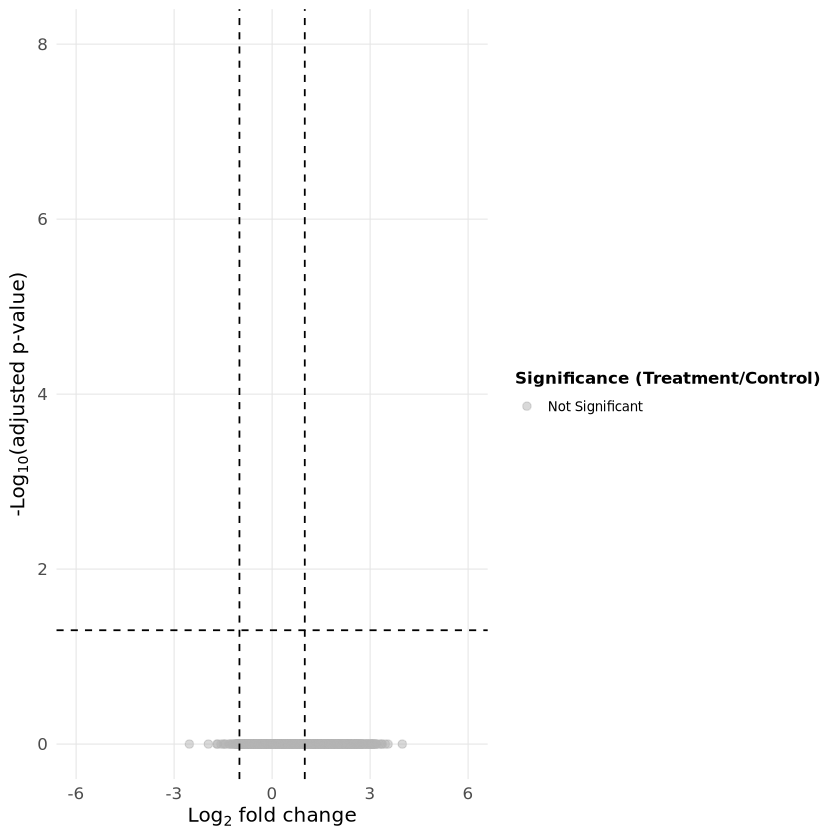

In [20]:
# Volcano